In [1]:
# Supervised Learning - General Overview (Classification + Regression)
# Datasets:
#   - Titanic: ../Datasets/Titanic-Dataset.csv  (classification example)
#   - California Housing: built into sklearn (regression example)
#
# Goal here isn't to build the best model - just to see the full supervised
# learning workflow end to end: train/test split -> fit -> predict -> evaluate

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)
from sklearn.datasets import fetch_california_housing

In [3]:
# ============================================================
# PART 1 - Classification (Titanic - predict Survived)
# ============================================================

df = pd.read_csv(r"C:\My-Data-Science-Portfolio\Datasets\Titanic-Dataset.csv")
#df = pd.read_csv("../Datasets/Titanic-Dataset.csv")
# ---- 1. Minimal cleaning (reusing logic from the preprocessing script) ----
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
df = pd.get_dummies(df, columns=["Embarked"], drop_first=True)

features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare",
            "Embarked_Q", "Embarked_S"]
X = df[features]
y = df["Survived"]

# ---- 2. Train/test split ----
# this is the core idea of supervised learning - train on one part,
# test on unseen data to see how well it actually generalizes
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train size:", X_train.shape, "Test size:", X_test.shape)

# ---- 3. Scale features (logistic regression is distance/gradient based) ----
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)   # transform only, never fit on test data

# ---- 4. Fit the model ----
clf = LogisticRegression(max_iter=1000, random_state=42)
clf.fit(X_train_scaled, y_train)

# ---- 5. Predict on test set ----
y_pred = clf.predict(X_test_scaled)

# ---- 6. Evaluate ----
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# ---- 7. Look at which features mattered most ----
coef_df = pd.DataFrame({
    "Feature": features,
    "Coefficient": clf.coef_[0]
}).sort_values("Coefficient", key=abs, ascending=False)
print(coef_df)

# Sex and Pclass usually end up as the strongest predictors of survival


Train size: (712, 8) Test size: (179, 8)
Accuracy: 0.8044692737430168

Confusion Matrix:
 [[98 12]
 [23 46]]

Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179

      Feature  Coefficient
1         Sex     1.269598
0      Pclass    -0.928698
2         Age    -0.502878
3       SibSp    -0.262672
7  Embarked_S    -0.171784
5        Fare     0.099599
6  Embarked_Q     0.080683
4       Parch    -0.067158


(20640, 9)
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64
MAE: 0.5332001304956565
RMSE: 0.7455813830127764
R2 Score: 0.5757877060324508


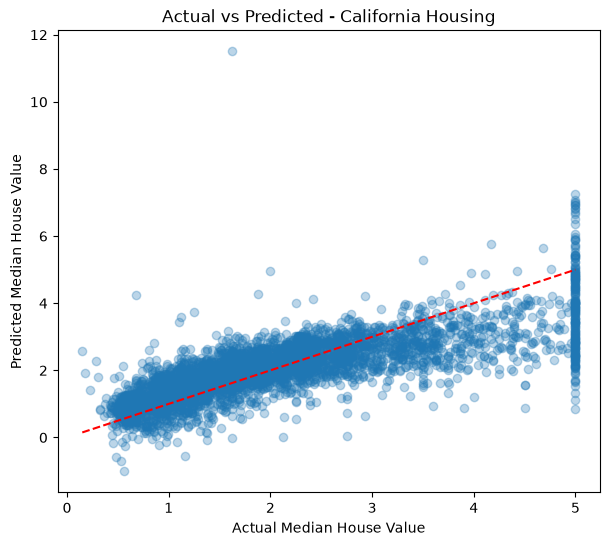

      Feature  Coefficient
6    Latitude    -0.896929
7   Longitude    -0.869842
0      MedInc     0.854383
3   AveBedrms     0.339259
2    AveRooms    -0.294410
1    HouseAge     0.122546
5    AveOccup    -0.040829
4  Population    -0.002308


In [4]:
# ============================================================
# PART 2 - Regression (California Housing - predict median house value)
# ============================================================

housing = fetch_california_housing(as_frame=True)
housing_df = housing.frame

print(housing_df.shape)
print(housing_df.head())
print(housing_df.isnull().sum())   # this dataset is already clean

X_house = housing_df.drop(columns=["MedHouseVal"])
y_house = housing_df["MedHouseVal"]

# ---- 8. Train/test split ----
Xh_train, Xh_test, yh_train, yh_test = train_test_split(
    X_house, y_house, test_size=0.2, random_state=42
)

# ---- 9. Scale features ----
scaler2 = StandardScaler()
Xh_train_scaled = scaler2.fit_transform(Xh_train)
Xh_test_scaled = scaler2.transform(Xh_test)

# ---- 10. Fit a regression model ----
reg = LinearRegression()
reg.fit(Xh_train_scaled, yh_train)

# ---- 11. Predict and evaluate ----
yh_pred = reg.predict(Xh_test_scaled)

print("MAE:", mean_absolute_error(yh_test, yh_pred))
print("RMSE:", np.sqrt(mean_squared_error(yh_test, yh_pred)))
print("R2 Score:", r2_score(yh_test, yh_pred))

# ---- 12. Actual vs predicted plot ----
plt.figure(figsize=(7, 6))
plt.scatter(yh_test, yh_pred, alpha=0.3)
plt.plot([yh_test.min(), yh_test.max()], [yh_test.min(), yh_test.max()], "r--")
plt.xlabel("Actual Median House Value")
plt.ylabel("Predicted Median House Value")
plt.title("Actual vs Predicted - California Housing")
plt.show()

# ---- 13. Feature importance (coefficients) ----
coef_df2 = pd.DataFrame({
    "Feature": X_house.columns,
    "Coefficient": reg.coef_
}).sort_values("Coefficient", key=abs, ascending=False)
print(coef_df2)
